In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv


In [2]:

# Load the Concrete Compressive Strength dataset
df = pd.read_csv('/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv')

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display the first 5 rows
df.head()


Dataset Shape: (1030, 9)

Column Names:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age', 'concrete_compressive_strength']


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


Missing Values:
cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64

Duplicate Rows: 25

Dataset Statistics:
            cement  blast_furnace_slag      fly_ash        water  \
count  1030.000000         1030.000000  1030.000000  1030.000000   
mean    281.167864           73.895825    54.188350   181.567282   
std     104.506364           86.279342    63.997004    21.354219   
min     102.000000            0.000000     0.000000   121.800000   
25%     192.375000            0.000000     0.000000   164.900000   
50%     272.900000           22.000000     0.000000   185.000000   
75%     350.000000          142.950000   118.300000   192.000000   
max     540.000000          359.400000   200.100000   247.000000   

  

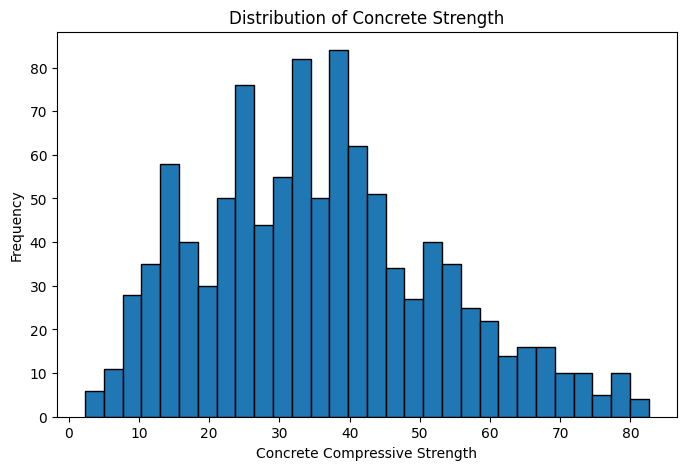

In [3]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Display statistical summary
print("\nDataset Statistics:")
print(df.describe())

# Visualize target distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['concrete_compressive_strength'],
         bins=30, edgecolor='black')
plt.xlabel('Concrete Compressive Strength')
plt.ylabel('Frequency')
plt.title('Distribution of Concrete Strength')
plt.show()


In [4]:

from sklearn.model_selection import train_test_split

# Remove missing values and exact duplicate rows
print("Original Rows:", len(df))
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

df_clean = df.dropna().drop_duplicates().copy()

# Separate features and target
X = df_clean.drop(columns=['concrete_compressive_strength'])
y = df_clean['concrete_compressive_strength']

# Split the dataset: 80% training, 20% testing
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Samples:", X_train_raw.shape[0])
print("Testing Samples:", X_test_raw.shape[0])
print("Number of Features:", X_train_raw.shape[1])


Original Rows: 1030
Missing Values: 0
Duplicate Rows: 25

Training Samples: 804
Testing Samples: 201
Number of Features: 8


In [5]:

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Generate polynomial features (degree = 2)
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_raw)
X_test_poly = poly.transform(X_test_raw)

# Standardize polynomial features
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Standardize the target for stable optimization
scaler_y = StandardScaler()

y_train = scaler_y.fit_transform(
    y_train_raw.to_numpy().reshape(-1, 1)
).ravel()

y_test = scaler_y.transform(
    y_test_raw.to_numpy().reshape(-1, 1)
).ravel()

# Display results
print("Polynomial Degree:", 2)
print("Original Features:", X_train_raw.shape[1])
print("Polynomial Features:", X_train_poly.shape[1])
print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)
print("Training Target Mean:", round(y_train.mean(), 4))


Polynomial Degree: 2
Original Features: 8
Polynomial Features: 44
Training Shape: (804, 44)
Testing Shape: (201, 44)
Training Target Mean: 0.0


In [6]:

# Batch Gradient Descent (GD) from Scratch

# Add bias column (x0 = 1)
X_train_gd = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

# Initialize parameters
m, n = X_train_gd.shape
theta_gd = np.zeros(n)

# Hyperparameters
learning_rate = 0.01
epochs = 2000

# Store cost values
cost_history_gd = []

# Batch Gradient Descent
for epoch in range(epochs):

    # Step 1: Calculate predictions
    predictions = X_train_gd @ theta_gd

    # Step 2: Calculate errors
    errors = predictions - y_train

    # Step 3: Calculate gradients
    gradients = (X_train_gd.T @ errors) / m

    # Step 4: Update all parameters
    theta_gd = theta_gd - learning_rate * gradients

    # Step 5: Calculate Cost Function
    new_predictions = X_train_gd @ theta_gd
    new_errors = new_predictions - y_train

    cost = np.sum(new_errors ** 2) / (2 * m)
    cost_history_gd.append(cost)

# Display results
print("Optimizer: Batch Gradient Descent")
print("Learning Rate:", learning_rate)
print("Epochs:", epochs)
print("Number of Parameters:", n)
print("Initial Cost:", round(cost_history_gd[0], 6))
print("Final Cost:", round(cost_history_gd[-1], 6))


Optimizer: Batch Gradient Descent
Learning Rate: 0.01
Epochs: 2000
Number of Parameters: 45
Initial Cost: 0.463785
Final Cost: 0.112916


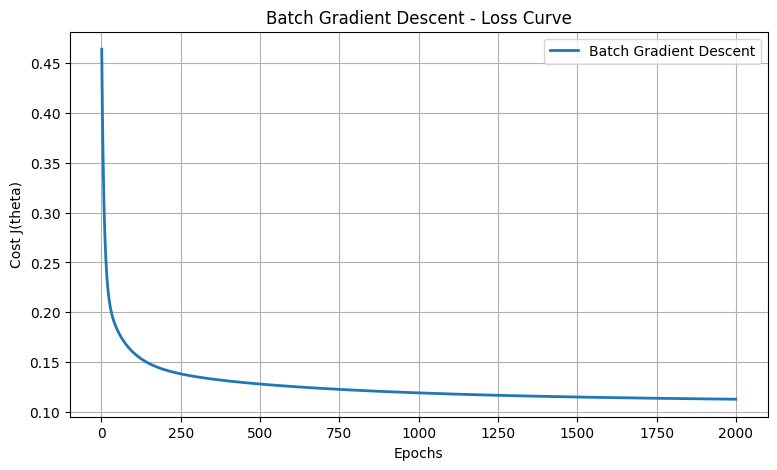

In [7]:

# Plot Batch Gradient Descent Loss Curve

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    cost_history_gd,
    label='Batch Gradient Descent',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('Batch Gradient Descent - Loss Curve')
plt.legend()
plt.grid(True)
plt.show()


In [8]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Add bias column to test data
X_test_gd = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

# Predict using trained GD parameters
y_pred_scaled = X_test_gd @ theta_gd

# Convert predictions to original scale
y_pred = scaler_y.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Actual test values
y_actual = y_test_raw.to_numpy()

# Evaluation metrics
mse_gd = mean_squared_error(y_actual, y_pred)
rmse_gd = np.sqrt(mse_gd)
mae_gd = mean_absolute_error(y_actual, y_pred)
r2_gd = r2_score(y_actual, y_pred)

print("Batch Gradient Descent - Test Results")
print("--------------------------------------")
print("MSE:", round(mse_gd, 4))
print("RMSE:", round(rmse_gd, 4))
print("MAE:", round(mae_gd, 4))
print("R2 Score:", round(r2_gd, 4))


Batch Gradient Descent - Test Results
--------------------------------------
MSE: 69.791
RMSE: 8.3541
MAE: 6.2905
R2 Score: 0.7661


In [9]:

# Batch Gradient Descent with Momentum

theta_momentum = np.zeros(n)
velocity = np.zeros(n)

beta = 0.9
cost_history_momentum = []

for epoch in range(epochs):

    predictions = X_train_gd @ theta_momentum
    errors = predictions - y_train

    gradients = (X_train_gd.T @ errors) / m

    # Momentum update
    velocity = beta * velocity + gradients

    # Update parameters
    theta_momentum -= learning_rate * velocity

    # Calculate cost
    new_errors = X_train_gd @ theta_momentum - y_train
    cost = np.mean(new_errors ** 2) / 2

    cost_history_momentum.append(cost)

# Evaluate Momentum on test data
y_pred_momentum_scaled = X_test_gd @ theta_momentum

y_pred_momentum = scaler_y.inverse_transform(
    y_pred_momentum_scaled.reshape(-1, 1)
).ravel()

rmse_momentum = np.sqrt(
    mean_squared_error(y_actual, y_pred_momentum)
)

r2_momentum = r2_score(y_actual, y_pred_momentum)

print("GD vs GD with Momentum")
print("-----------------------------")
print("GD Final Cost:", round(cost_history_gd[-1], 6))
print("Momentum Final Cost:", round(cost_history_momentum[-1], 6))
print("GD Test RMSE:", round(rmse_gd, 4))
print("Momentum Test RMSE:", round(rmse_momentum, 4))
print("GD Test R2:", round(r2_gd, 4))
print("Momentum Test R2:", round(r2_momentum, 4))


GD vs GD with Momentum
-----------------------------
GD Final Cost: 0.112916
Momentum Final Cost: 0.105341
GD Test RMSE: 8.3541
Momentum Test RMSE: 8.2723
GD Test R2: 0.7661
Momentum Test R2: 0.7706


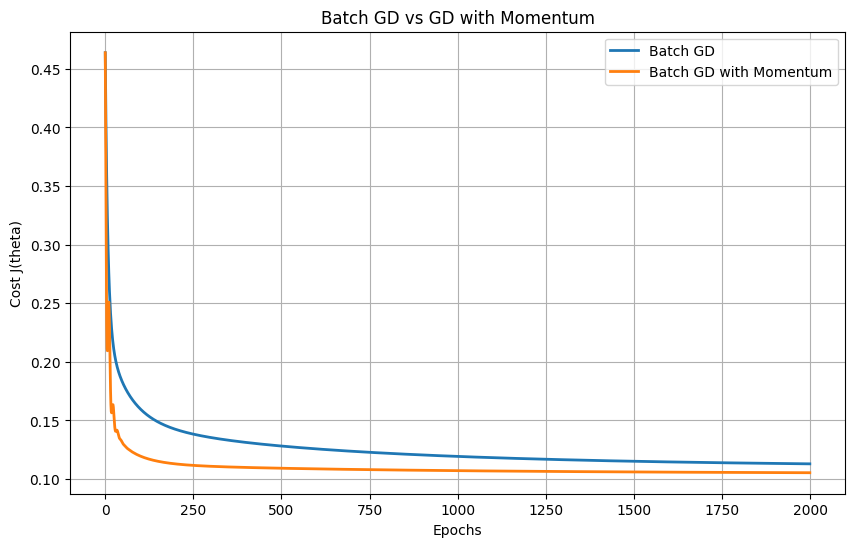

In [10]:

# Compare GD and GD with Momentum

plt.figure(figsize=(10, 6))

plt.plot(
    cost_history_gd,
    label='Batch GD',
    linewidth=2
)

plt.plot(
    cost_history_momentum,
    label='Batch GD with Momentum',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('Batch GD vs GD with Momentum')
plt.legend()
plt.grid(True)
plt.show()



## Results and Discussion

In this experiment, Polynomial Regression (degree = 2) was trained using Batch Gradient Descent (GD) and GD with Momentum.

### Experimental Results

| Metric | GD | GD with Momentum |
|---|---|---|
| Final Training Cost | 0.112916 | 0.105341 |
| Test RMSE | 8.3541 | 8.2723 |
| Test R² | 0.7661 | 0.7706 |

### Discussion

Batch Gradient Descent successfully reduced the training cost over 2000 epochs.

Adding Momentum (beta = 0.9) accelerated convergence and achieved a lower final training cost.

The Momentum model also achieved a slightly lower test RMSE and a higher R² score.

### Conclusion

Both methods successfully optimized the Polynomial Regression model.

GD with Momentum demonstrated faster convergence and slightly better predictive performance in this experiment.

These results highlight the benefit of incorporating previous gradient information into parameter updates.
